# 301. Kill test 1: can kmerseek pin the start and end of short protein features?

**The question.** Given a whole protein, can kmerseek report the start and end of its short
features (signal peptides, transit peptides, transmembrane spans, ELM short linear motifs)
to within 4 residues, at a false-positive rate on decoys below 1%, faster than the CPU tools
people use now?

**The decision this informs.** Whether the paper can offer kmerseek as a tool that places
short features on a protein. If it fails, that use comes out of the paper, and kmerseek is
described only as a search that finds related proteins.

**Words.**
- A *kmerseek setting* is one combination of alphabet, k-size, scaled, extension and mask.
- A *feature* is a Swiss-Prot or ELM annotated stretch shorter than 60 residues.
- A *region* is the stretch kmerseek reports for a hit. For the scans below, the stretch a
  scan reports is called a *call*.
- *Boundary error* is |predicted start − true start| + |predicted end − true end|, in
  residues. 0 is perfect; larger is worse.
- A *decoy window* is a feature's own residues put back into its parent protein in a new
  order (step 3). A hit on a decoy window is a false positive.

**The pass/fail rule, fixed before any kmerseek run (task brief, 2026-10-20).** Set a
regional E-value threshold at which fewer than 1.0% of decoy windows produce a hit. At that
threshold:

PASS if all three hold:
1. kmerseek recalls more than 80% of true features. A feature is recalled when a reported
   region overlaps it by at least one residue; the overlap fraction is reported too.
2. Median boundary error is 4 residues or fewer.
3. One whole-protein query takes under 100 ms wall-clock on 4 CPU cores with a cold disk
   cache.

DROP THE IDEA if recall falls below 50% at that threshold, or if median boundary error is 8
residues or more. Anything in between is FAIL, reported with the numbers. The rule is not
changed after the first result. If it turns out to be the wrong rule, this notebook says so
and still reports the verdict under it.

Higher recall is better. Lower boundary error is better. A method whose recall equals its
decoy hit rate is no better than chance.

**Status, 2026-10-20.** Step 1 (the scans) is done and below. Steps 2 to 8 (the 2,000 + 500
query set, decoys for it, the database, kmerseek and the two comparators, the second-agent
check) have not run; the last section lists what was found while preparing them.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(200)

TABLES = Path("../tables")
DATA = Path("../data/301_short_feature_boundaries")
FIG = Path("../figures")

curve = pl.read_csv(TABLES / "301_step1_scan_curve_nb244_swissprot.csv")
feats = pl.read_csv(TABLES / "301_step1_scan_features_nb244_swissprot.csv")
summary = pl.read_csv(TABLES / "301_step1_scan_summary_nb244_swissprot.csv")
cases = pl.read_csv(DATA / "step1_cases_nb244_swissprot.tsv", separator="\t")

SCAN_COLOUR = {"hydropathy": pf.OKABE_ITO["blue"], "period": pf.OKABE_ITO["vermillion"]}
SCAN_LABEL = {
    "hydropathy": "hydropathy window scan (Kyte-Doolittle, 19 aa)",
    "period": "period scan (H/P autocorrelation, 19 aa, lags 1-9)",
}
DECOY_RULE = "decoy hit rate below 1%"
KD_RULE = "Kyte-Doolittle 1982 cutoff 1.6 (context, not the pass rule)"
DECOY_LIMIT = 0.01
RECALL_PASS, RECALL_DROP = 0.80, 0.50
ERROR_PASS, ERROR_DROP = 4, 8


def read_fasta(path):
    seqs, acc = {}, None
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            acc = line[1:].split()[0]
            seqs[acc] = []
        else:
            seqs[acc].append(line.strip())
    return {k: "".join(v) for k, v in seqs.items()}


human = read_fasta(DATA / "step1_queries_nb244_human_swissprot.fasta")
decoy_seqs = read_fasta(DATA / "step1_decoys_nb244_swissprot.fasta")

## 1. Step 1: the scans that need no search, on notebook 244's 87 cases

[Notebook 231](https://github.com/seanome/2024-kmerseek-analysis/blob/main/notebooks/231_swissprot_composition_controls.ipynb)
showed a Kyte-Doolittle hydropathy window beat all 406 kmerseek settings on Swiss-Prot.
[Notebook 244](https://github.com/seanome/2024-kmerseek-analysis/pull/78) named that scan as
the control for its 87 short-feature cases and recorded only whether it landed on them (1 of
87), not its recall at a fixed false-positive rate or its boundary error. This section
records both, for that scan and for a period scan, under the pass rule above. Their numbers
are the bar for kmerseek.

**Data.** The 87 rows of notebook 244's candidate table admitted under "all criteria"
(`tables/244_hero_candidates.csv`, PR 78 at commit 9e6434f5), copied to
`data/301_short_feature_boundaries/step1_cases_nb244_swissprot.tsv`, and their human
Swiss-Prot sequences (`step1_queries_nb244_human_swissprot.fasta`, from the same commit's
`244_case_sequences.fasta`). The midi-plus run, 998 human chr6/MHC-region queries, Swiss-Prot
features. A case is one human feature in one target species. A scan reads only the human
protein, so it gives the same answer for every species of a feature: the 87 cases are 50
distinct human features on 42 proteins. Recall is given both ways.

**The scans** (`scripts/score_301_step1_scans.py`). Both slide a 19-residue window, notebook
231's window.
- Hydropathy: the window's mean Kyte-Doolittle hydropathy.
- Period: the protein written as hydrophobic +1 / polar −1 in hp_pbotc_1st_ed2's classes
  (hydrophobic `ACFILMPVWY`, polar `DEGHKNQRST`), as in
  [notebook 295](https://github.com/seanome/2024-kmerseek-analysis/pull/141)'s period scan. The
  window's score is its largest autocorrelation over lags 1 to 9 (the mean of x[i]·x[i+lag]
  over the pairs inside the window). Notebook 295 used lags 1 to 30 on whole proteins; a
  19-residue window has no lag 30, and lags past 9 have fewer than 10 pairs.

A call is every run of windows scoring above the threshold, reported as the residues those
windows cover. The threshold is the lowest one at which fewer than 1% of decoy windows are
hit.

**Decoys** (step 3's recipe, applied to these 50 features). For each feature, two copies of
the parent protein with the feature's residues replaced by (a) a di-residue shuffle: the
window cut into adjacent pairs and the pairs put in random order (seed 301), and (b) the
window reversed. That is 100 decoy windows, so "fewer than 1%" means none hit.

The feature types of the 87 cases are not the four types of the main test (signal peptides,
transit peptides, transmembrane spans, ELM motifs). Only 4 of the 87 are TRANSMEM; none is a
signal or transit peptide or an ELM motif.

shape: (7, 4)
┌──────────────┬─────────┬────────────┬──────────────────┐
│ feature_type ┆ n_cases ┆ n_features ┆ median_length_aa │
│ ---          ┆ ---     ┆ ---        ┆ ---              │
│ str          ┆ u32     ┆ u32        ┆ f64              │
╞══════════════╪═════════╪════════════╪══════════════════╡
│ BINDING      ┆ 31      ┆ 9          ┆ 9.0              │
│ INTRAMEM     ┆ 16      ┆ 6          ┆ 20.0             │
│ ZN_FING      ┆ 13      ┆ 11         ┆ 23.0             │
│ REPEAT       ┆ 13      ┆ 12         ┆ 33.0             │
│ DOMAIN       ┆ 8       ┆ 7          ┆ 51.0             │
│ TRANSMEM     ┆ 4       ┆ 4          ┆ 21.0             │
│ DNA_BIND     ┆ 2       ┆ 1          ┆ 24.0             │
└──────────────┴─────────┴────────────┴──────────────────┘
total: 87 cases, 50 features, 42 proteins


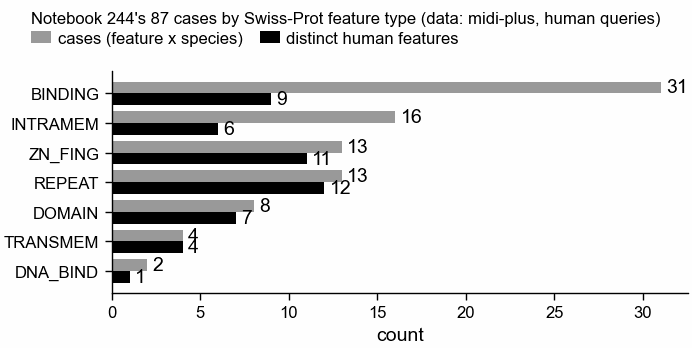

In [2]:
by_type = (
    cases.group_by("feature_type")
    .agg(
        n_cases=pl.len(),
        n_features=pl.struct("query", "feature_start", "feature_end").n_unique(),
        median_length_aa=pl.col("feature_length_aa").median(),
    )
    .sort("n_cases", descending=True)
)
print(by_type)
print(
    f"total: {cases.height} cases, "
    f"{cases.select('query', 'feature_start', 'feature_end').n_unique()} features, "
    f"{cases['query'].n_unique()} proteins"
)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 45)
y = np.arange(by_type.height)
ax.barh(
    y - 0.2,
    by_type["n_cases"],
    height=0.4,
    color=pf.GREY,
    label="cases (feature x species)",
)
ax.barh(
    y + 0.2,
    by_type["n_features"],
    height=0.4,
    color="black",
    label="distinct human features",
)
ax.set_yticks(y, by_type["feature_type"])
ax.invert_yaxis()
ax.set_xlabel("count")
for yi, (c, f) in enumerate(zip(by_type["n_cases"], by_type["n_features"])):
    ax.text(c + 0.3, yi - 0.2, str(c), va="center")
    ax.text(f + 0.3, yi + 0.2, str(f), va="center")
pf.shared_legend(
    fig,
    ncol=2,
    title=(
        "Notebook 244's 87 cases by Swiss-Prot feature type (data: midi-plus, human queries)"
    ),
    alignment="left",
)
pf.save(fig, FIG / "301_step1_case_types_nb244_swissprot", formats=("png", "pdf"))

### SF1. Recall against decoy hit rate, for each scan

How to read it: each curve traces one scan as its threshold moves from strict (bottom left)
to loose (top right). The grey dashed diagonal is a scan whose recall equals its decoy hit
rate, which is no better than chance. The pass rule reads each curve at the black dotted
line, a decoy hit rate of 1%. Above the diagonal is better than chance; the pass rule needs
recall above 0.8 left of the dotted line. Panel a pools all 50 features; panels b to h split
them by Swiss-Prot feature type, with the number of features in each title.

Features whose real window score is above both of its decoys' scores:
shape: (7, 4)
┌──────────────┬────────────┬────────────┬────────┐
│ feature_type ┆ n_features ┆ hydropathy ┆ period │
│ ---          ┆ ---        ┆ ---        ┆ ---    │
│ str          ┆ i64        ┆ i64        ┆ i64    │
╞══════════════╪════════════╪════════════╪════════╡
│ BINDING      ┆ 9          ┆ 0          ┆ 2      │
│ INTRAMEM     ┆ 6          ┆ 0          ┆ 0      │
│ ZN_FING      ┆ 11         ┆ 2          ┆ 4      │
│ REPEAT       ┆ 12         ┆ 3          ┆ 1      │
│ DOMAIN       ┆ 7          ┆ 2          ┆ 1      │
│ TRANSMEM     ┆ 4          ┆ 1          ┆ 1      │
│ DNA_BIND     ┆ 1          ┆ 0          ┆ 0      │
└──────────────┴────────────┴────────────┴────────┘
shape: (2, 3)
┌────────────┬──────────────────────────┬────────────┐
│ scan       ┆ n_real_beats_both_decoys ┆ n_features │
│ ---        ┆ ---                      ┆ ---        │
│ str        ┆ i64                      ┆ i64        │
╞═════

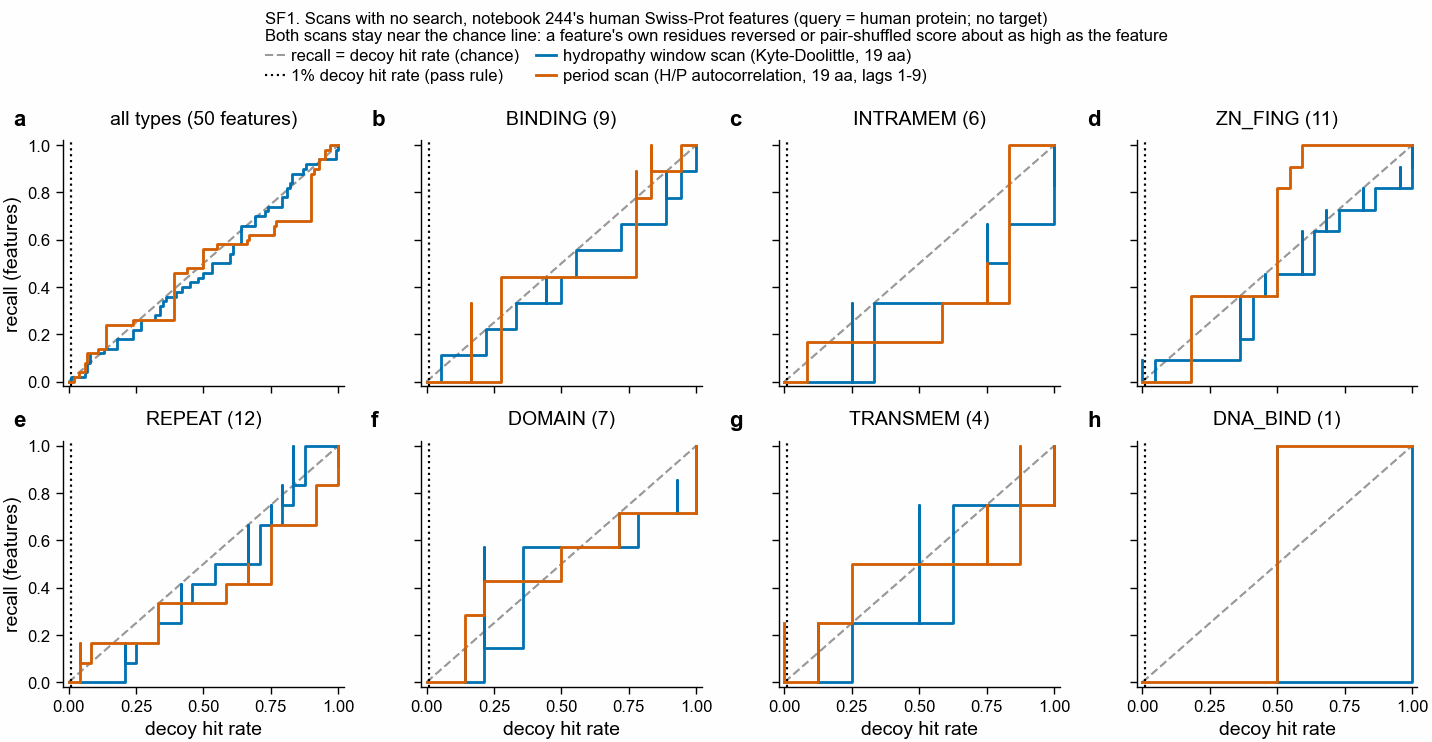

In [3]:
types = by_type["feature_type"].to_list()
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, nrows=2, ncols=4, sharex=True, sharey=True)
axs = axs.ravel()


def draw(ax, rows_by_scan, title):
    ax.plot(
        [0, 1],
        [0, 1],
        color=pf.GREY,
        ls="--",
        lw=0.8,
        label="recall = decoy hit rate (chance)",
    )
    ax.axvline(
        DECOY_LIMIT,
        color="black",
        ls=":",
        lw=0.8,
        label="1% decoy hit rate (pass rule)",
    )
    for scan, (x, yv) in rows_by_scan.items():
        ax.step(x, yv, where="post", color=SCAN_COLOUR[scan], label=SCAN_LABEL[scan])
    ax.set_title(title)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)


def curve_for(f_best, d_best):
    grid = np.unique(np.concatenate([f_best, d_best, [-np.inf]]))
    x = np.array([(d_best > t).mean() for t in grid])
    yv = np.array([(f_best > t).mean() for t in grid])
    o = np.argsort(x, kind="stable")
    return x[o], yv[o]


# Pooled curves come from the scoring script's own table.
pooled = {}
for scan in SCAN_COLOUR:
    c = curve.filter(pl.col("scan") == scan).sort("decoy_hit_rate", "recall_features")
    pooled[scan] = (c["decoy_hit_rate"].to_numpy(), c["recall_features"].to_numpy())
draw(axs[0], pooled, "all types (50 features)")

# Per type: recompute from the per-feature best window scores and the decoy sequences.
sys.path.insert(0, str(Path("../scripts").resolve()))
import score_301_step1_scans as s1

decoy_best = {}
fb = feats.filter(pl.col("threshold_rule") == DECOY_RULE)
for scan, fn in s1.SCANS.items():
    for r in fb.filter(pl.col("scan") == scan).iter_rows(named=True):
        key = f"{r['query']}|{r['feature_start']}-{r['feature_end']}"
        decoy_best[(scan, r["feature_id"])] = [
            s1.best_window_over(
                fn(decoy_seqs[f"{key}|{k}"]), r["feature_start"], r["feature_end"]
            )
            for k in ("dishuffle", "reversed")
        ]
per_type_rows = []
for ax, t in zip(axs[1:], types):
    rows = {}
    for scan in SCAN_COLOUR:
        sub = fb.filter((pl.col("scan") == scan) & (pl.col("feature_type") == t))
        f_best = sub["best_window_score"].to_numpy()
        d_best = np.array(
            [v for fid in sub["feature_id"] for v in decoy_best[(scan, fid)]]
        )
        rows[scan] = curve_for(f_best, d_best)
        n_beats = int(
            sum(
                f > max(decoy_best[(scan, fid)])
                for f, fid in zip(f_best, sub["feature_id"])
            )
        )
        per_type_rows.append(
            {
                "scan": scan,
                "feature_type": t,
                "n_features": sub.height,
                "n_real_beats_both_decoys": n_beats,
            }
        )
    draw(ax, rows, f"{t} ({sub.height})")
for ax in axs[len(types) + 1 :]:
    ax.set_visible(False)
for ax in axs[4:]:
    ax.set_xlabel("decoy hit rate")
for ax in axs[::4]:
    ax.set_ylabel("recall (features)")
for ax, letter in zip(axs, "abcdefgh"):
    if ax.get_visible():
        pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=2,
    title=(
        "SF1. Scans with no search, notebook 244's human Swiss-Prot features (query = human protein; no target)\n"
        "Both scans stay near the chance line: a feature's own residues reversed or pair-shuffled score about as high as the feature"
    ),
    alignment="left",
)
pf.save(
    fig,
    FIG / "301_sf1_scan_recall_vs_decoy_rate_nb244_swissprot",
    formats=("png", "pdf"),
)

beats = pl.DataFrame(per_type_rows)
print("Features whose real window score is above both of its decoys' scores:")
print(
    beats.pivot(
        on="scan",
        index=["feature_type", "n_features"],
        values="n_real_beats_both_decoys",
    )
)
print(
    beats.group_by("scan").agg(
        pl.col("n_real_beats_both_decoys").sum(), pl.col("n_features").sum()
    )
)
gap = (
    curve.with_columns(gap=pl.col("recall_features") - pl.col("decoy_hit_rate"))
    .group_by("scan")
    .agg(largest_recall_minus_decoy_rate=pl.col("gap").max().round(3))
)
print(gap)

### The pass rule applied to the scans

The table is `tables/301_step1_scan_summary_nb244_swissprot.csv`, column names as the scoring
script wrote them. `recall_features` counts the 50 distinct features; `recall_cases` weights
each by its number of species in the 87 cases. `ms_per_protein_warm` is the scan's time per
protein on the laptop, one core, sequences in memory: a warm number, not the cold-cache
timing of the pass rule.

The Kyte-Doolittle row at threshold 1.6 is context only. 1.6 is Kyte and Doolittle's 1982
cutoff for a membrane-spanning window, the one notebook 231 used; it is not set on decoys.

shape: (3, 11)
┌────────────┬──────────────────────┬───────────┬──────────────┬─────────────────┬────────────────┬─────────────────┬──────────────┬──────────────────────┬──────────────────────┬─────────────────────┐
│ scan       ┆ threshold_rule       ┆ threshold ┆ n_decoys_hit ┆ n_decoy_windows ┆ decoy_hit_rate ┆ recall_features ┆ recall_cases ┆ median_boundary_erro ┆ median_overlap_fract ┆ ms_per_protein_warm │
│ ---        ┆ ---                  ┆ ---       ┆ ---          ┆ ---             ┆ ---            ┆ ---             ┆ ---          ┆ r_aa                 ┆ ion                  ┆ ---                 │
│ str        ┆ str                  ┆ f64       ┆ i64          ┆ i64             ┆ f64            ┆ f64             ┆ f64          ┆ ---                  ┆ ---                  ┆ f64                 │
│            ┆                      ┆           ┆              ┆                 ┆                ┆                 ┆              ┆ f64                  ┆ f64                  ┆   

hydropathy: recall 0.00 of features (0.00 of cases), median boundary error None aa -> DROP
period: recall 0.00 of features (0.00 of cases), median boundary error None aa -> DROP


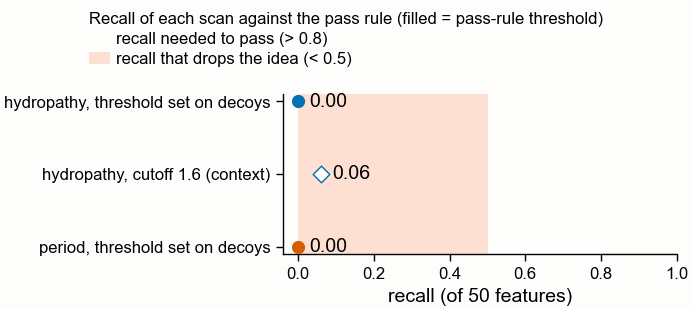

In [4]:
show = summary.select(
    "scan",
    "threshold_rule",
    pl.col("threshold").round(3),
    "n_decoys_hit",
    "n_decoy_windows",
    "decoy_hit_rate",
    "recall_features",
    pl.col("recall_cases").round(3),
    "median_boundary_error_aa",
    pl.col("median_overlap_fraction").round(2),
    pl.col("ms_per_protein_warm").round(3),
)
print(show)


def verdict(recall, err):
    if recall < RECALL_DROP or (err is not None and err >= ERROR_DROP):
        return "DROP"
    if recall > RECALL_PASS and err is not None and err <= ERROR_PASS:
        return "PASS (timing not tested)"
    return "FAIL"


fig, ax = pf.figure(pf.ONE_COLUMN_MM, 40)
ax.axvspan(RECALL_PASS, 1.0, color="#e5f5e0", label="recall needed to pass (> 0.8)")
ax.axvspan(0, RECALL_DROP, color="#fee0d2", label="recall that drops the idea (< 0.5)")
rows = summary.with_row_index("i")
for r in rows.iter_rows(named=True):
    marker = "o" if r["threshold_rule"] == DECOY_RULE else "D"
    face = SCAN_COLOUR[r["scan"]] if r["threshold_rule"] == DECOY_RULE else "white"
    ax.scatter(
        r["recall_features"],
        r["i"],
        marker=marker,
        s=18,
        color=face,
        edgecolor=SCAN_COLOUR[r["scan"]],
        zorder=3,
    )
    ax.annotate(
        f"{r['recall_features']:.2f}",
        (r["recall_features"], r["i"]),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
    )
ax.set_yticks(
    rows["i"],
    [
        f"{r['scan']}, "
        + (
            "threshold set on decoys"
            if r["threshold_rule"] == DECOY_RULE
            else "cutoff 1.6 (context)"
        )
        for r in rows.iter_rows(named=True)
    ],
)
ax.invert_yaxis()
ax.set_xlim(-0.04, 1)
ax.set_xlabel("recall (of 50 features)")
pf.shared_legend(
    fig,
    ncol=1,
    title=("Recall of each scan against the pass rule (filled = pass-rule threshold)"),
    alignment="left",
)
pf.save(
    fig,
    FIG / "301_step1_scan_recall_vs_pass_rule_nb244_swissprot",
    formats=("png", "pdf"),
)

for r in summary.filter(pl.col("threshold_rule") == DECOY_RULE).iter_rows(named=True):
    print(
        f"{r['scan']}: recall {r['recall_features']:.2f} of features "
        f"({r['recall_cases']:.2f} of cases), median boundary error "
        f"{r['median_boundary_error_aa']} aa -> {verdict(r['recall_features'], r['median_boundary_error_aa'])}"
    )

### SF2. Boundary error of the features a scan called

How to read it: one point per feature a scan called, at its boundary error. Left of the
4-residue line meets the pass rule's second condition; right of the 8-residue line is a DROP.
Lower is better. At the decoy-set threshold neither scan calls any feature, so that panel is
empty; panel b shows the hydropathy scan at its published 1.6 cutoff, the only setting with
any calls.

shape: (3, 11)
┌────────────┬─────────────────────────────────┬─────────┬────────┬──────────────┬───────────────┬─────────────┬────────────┬──────────┬────────────┬───────────────────┐
│ scan       ┆ threshold_rule                  ┆ gene    ┆ query  ┆ feature_type ┆ feature_start ┆ feature_end ┆ call_start ┆ call_end ┆ overlap_aa ┆ boundary_error_aa │
│ ---        ┆ ---                             ┆ ---     ┆ ---    ┆ ---          ┆ ---           ┆ ---         ┆ ---        ┆ ---      ┆ ---        ┆ ---               │
│ str        ┆ str                             ┆ str     ┆ str    ┆ str          ┆ i64           ┆ i64         ┆ i64        ┆ i64      ┆ i64        ┆ i64               │
╞════════════╪═════════════════════════════════╪═════════╪════════╪══════════════╪═══════════════╪═════════════╪════════════╪══════════╪════════════╪═══════════════════╡
│ hydropathy ┆ Kyte-Doolittle 1982 cutoff 1.6… ┆ KCNK5   ┆ O95279 ┆ INTRAMEM     ┆ 85            ┆ 112         ┆ 112        ┆ 134      

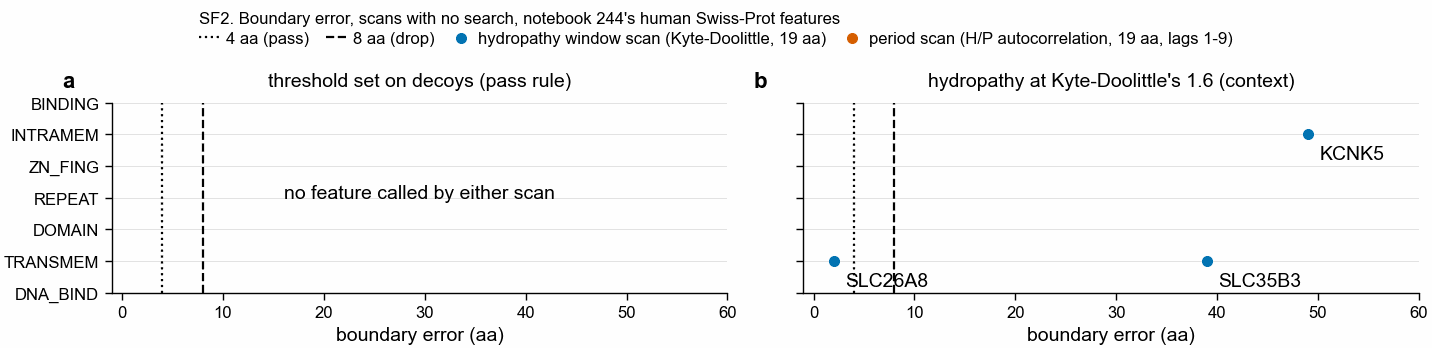

In [5]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 45, ncols=2, sharey=True)
for ax, rule, title in zip(
    axs,
    [DECOY_RULE, KD_RULE],
    [
        "threshold set on decoys (pass rule)",
        "hydropathy at Kyte-Doolittle's 1.6 (context)",
    ],
):
    ax.axvline(ERROR_PASS, color="black", ls=":", lw=0.8, label="4 aa (pass)")
    ax.axvline(ERROR_DROP, color="black", ls="--", lw=0.8, label="8 aa (drop)")
    sub = feats.filter((pl.col("threshold_rule") == rule) & pl.col("recalled"))
    for scan in SCAN_COLOUR:
        s = sub.filter(pl.col("scan") == scan)
        yv = [types.index(t) for t in s["feature_type"]]
        ax.scatter(
            s["boundary_error_aa"],
            yv,
            color=SCAN_COLOUR[scan],
            s=12,
            label=SCAN_LABEL[scan],
            zorder=3,
        )
        for x, yy, g in zip(s["boundary_error_aa"], yv, s["gene"]):
            ax.annotate(g, (x, yy), xytext=(4, -9), textcoords="offset points")
    if sub.height == 0:
        ax.text(
            0.5,
            0.5,
            "no feature called by either scan",
            transform=ax.transAxes,
            ha="center",
        )
    ax.set_yticks(range(len(types)), types)
    ax.set_xlim(-1, 60)
    ax.set_xlabel("boundary error (aa)")
    ax.set_title(title)
    ax.grid(axis="y", color="#dddddd", lw=0.3)
axs[0].invert_yaxis()
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=4,
    title=(
        "SF2. Boundary error, scans with no search, notebook 244's human Swiss-Prot features"
    ),
    alignment="left",
)
pf.save(
    fig, FIG / "301_sf2_scan_boundary_error_nb244_swissprot", formats=("png", "pdf")
)
print(
    feats.filter(pl.col("recalled")).select(
        "scan",
        "threshold_rule",
        "gene",
        "query",
        "feature_type",
        "feature_start",
        "feature_end",
        "call_start",
        "call_end",
        "overlap_aa",
        "boundary_error_aa",
    )
)

### The residues of every feature a scan called

For each call: the human feature's residues and the call's residues on the same protein
(1-based, inclusive), with `|` under the residues the two share. Then the feature reversed,
as it sits in its decoy, with the best 19-residue hydropathy window over it. Windows that lie
wholly inside the feature have the same means when the feature is reversed. Windows that
reach into the flanks change, which is why the reversed copy can score a little higher than
the real feature.

In [6]:
called = feats.filter((pl.col("threshold_rule") == KD_RULE) & pl.col("recalled"))
for r in called.iter_rows(named=True):
    p = human[r["query"]]
    s, e, cs, ce = r["feature_start"], r["feature_end"], r["call_start"], r["call_end"]
    lo, hi = min(s, cs), max(e, ce)
    feat_line = "".join(p[i - 1] if s <= i <= e else " " for i in range(lo, hi + 1))
    call_line = "".join(p[i - 1] if cs <= i <= ce else " " for i in range(lo, hi + 1))
    match = "".join(
        "|" if (s <= i <= e and cs <= i <= ce) else " " for i in range(lo, hi + 1)
    )
    print(
        f"{r['gene']} {r['query']} {r['feature_type']}  feature {s}-{e} ({e - s + 1} aa), "
        f"call {cs}-{ce}, {r['overlap_aa']} of {e - s + 1} feature residues inside the call, "
        f"boundary error {r['boundary_error_aa']} aa"
    )
    print(f"  feature {lo:>5} {feat_line}")
    print(f"          {'':>5} {match}")
    print(f"  call    {lo:>5} {call_line}")
    key = f"{r['query']}|{s}-{e}|reversed"
    real_best = s1.best_window_over(s1.hydropathy_windows(p), s, e)
    rev_best = s1.best_window_over(s1.hydropathy_windows(decoy_seqs[key]), s, e)
    print(f"  reversed {p[s - 1:e][::-1]}")
    print(
        f"  best window mean over the feature: real {real_best:.2f}, reversed decoy {rev_best:.2f}\n"
    )

KCNK5 O95279 INTRAMEM  feature 85-112 (28 aa), call 112-134, 1 of 28 feature residues inside the call, boundary error 49 aa
  feature    85 WPNAMIFAATVITTIGYGNVAPKTPAGR                      
                                           |                      
  call       85                            RLFCVFYGLFGVPLCLTWISALG
  reversed RGAPTKPAVNGYGITTIVTAAFIMANPW
  best window mean over the feature: real 1.67, reversed decoy 1.86

SLC26A8 Q96RN1 TRANSMEM  feature 393-413 (21 aa), call 393-411, 19 of 21 feature residues inside the call, boundary error 2 aa
  feature   393 LIAIGLCNVVSSFFRSCVFTG
                |||||||||||||||||||  
  call      393 LIAIGLCNVVSSFFRSCVF  
  reversed GTFVCSRFFSSVVNCLGIAIL
  best window mean over the feature: real 1.77, reversed decoy 1.88

SLC35B3 Q9H1N7 TRANSMEM  feature 324-346 (23 aa), call 299-332, 9 of 23 feature residues inside the call, boundary error 39 aa
  feature   299                          LIAVTVTTGRKAMTIVLSFIFFA
                               

### Step 1 verdict

- At the threshold where fewer than 1% of the 100 decoy windows are hit, the hydropathy
  window scan recalls 0 of 50 features (0 of 87 cases), and so does the period scan. Under
  the pass rule both are DROP: recall is below 50%. Neither meets the pass rule, so kmerseek
  is not held to a scan's bar on these cases; it is held to HMMER and MMseqs2 as planned.
- The scans fail for one reason. A feature's best window scores no higher than the best
  window of its own residues reversed or pair-shuffled. In SF1a, recall is never more than
  0.05 (hydropathy) or 0.10 (period) above the decoy hit rate at any threshold. A scan that reads composition over a window cannot pass a test whose decoys
  keep the composition.
- At Kyte and Doolittle's own cutoff of 1.6 the hydropathy scan calls 3 of 50 features and
  hits 7 of 100 decoy windows. Its boundary errors on those 3 are 2, 39 and 49 residues
  (SF2b). These cases are mostly not membrane features, which is why notebook 244 chose them.
- The 87 cases are not the main test's feature types. They are BINDING (31), INTRAMEM (16),
  REPEAT (13), ZN_FING (13), DOMAIN (8), TRANSMEM (4) and DNA_BIND (2). No signal peptide,
  transit peptide or ELM motif. The step 2 query set is where the scans meet the four main
  types; step 1 does not tell us how a scan does on signal peptides.

## 2. Steps 2 to 8: what was found while preparing them

These steps have not run. Six things in the task brief do not match the repository as it
stands on 2026-10-20. Each needs a decision before compute is spent.

1. **The decoys put the feature back into its real flanks.** Step 3 splices each decoy
   window into the parent protein. A homology search (MMseqs2, hmmscan, kmerseek with
   extension) that aligns the parent's homologs across the whole protein will report a
   region over the decoy window too, because the flanks are unchanged. Such a region counts
   as a decoy hit, so the 1% threshold will be set by whole-protein alignments, not by
   anything the feature's residues did. The scans above do not have this problem, because
   they read only the window.
2. **Which settings table.** Notebooks 250-253 (PRs 58, 69, 72) searched 19 settings, one
   per alphabet (`assets/elm_cover_chosen_arms.tsv`), none with extension. The count "81 of
   152 settings had no Karlin-Altschul fit" is from notebook 241's 152 settings, not from
   250-253.
3. **PR 54 is not the E-value source.** seanome/kmerseek PR 54 ("Extend matched regions past
   their exact seed, and rank them with a Karlin-Altschul E-value") was closed without
   merging. The region E-values now come from kmerseek PRs 133/134 (commit 0a22970). Notebook
   344 (PR 174) found those E-values 10-113 times too small on long, low-complexity proteins.
   The pass rule sets its threshold on decoys, so it uses the E-value only to rank regions;
   miscalibration does not change the verdict.
4. **UniRef90 may not fit two compute-days.** UniRef90 holds far more sequences than
   Swiss-Prot (its exact size is recorded on the day it is downloaded). No kmerseek index of
   that size has been built in this project. Its memory and time have to be measured on
   Swiss-Prot first and scaled before the UniRef90 run is sized.
5. **hmmscan has no database to share.** hmmscan searches each query against Pfam-A
   profiles, not against UniRef90, so "the same database" applies only to MMseqs2. Pfam has
   few families for signal or transit peptides, so hmmscan is expected to report little on
   those types.
6. **Cold cache on Sherlock.** Shared nodes do not let a user drop the page cache, so a
   cold-cache timing needs a freshly allocated node whose first read of the index is timed.
   If that cannot be confirmed, timings will be labelled warm.

### Decisions, 2026-10-20, before any kmerseek run

Olga's answers to points 1, 2 and 4 above. They are part of the rule from here on.

- **Decoy hit (point 1).** The verdict is reported under the brief's rule: a decoy is hit
  when any reported region overlaps its window. Beside it, labelled as not the rule, the
  same numbers with a region counted only when at least half its residues lie inside the
  window, for decoys and true features alike.
- **Settings (point 2).** Notebook 241's 152 settings. Those without a Karlin-Altschul fit
  (81 of 152 in notebook 241) are excluded and listed by name.
- **Database (point 4).** Swiss-Prot first, with every query's own UniRef90 cluster
  removed. Index memory and time are measured there, and UniRef90 is run only if the
  measurement shows it fits the compute left.

## Summary and conclusions

1. On notebook 244's 87 cases (50 human Swiss-Prot features), the hydropathy window scan and
   the period scan each recall 0 features at a decoy hit rate below 1%: DROP under the pass
   rule (SF1, table in section 1).
2. Both scans score a feature's reversed or pair-shuffled residues about as high as the
   feature itself: at every threshold, recall is at most 0.05 (hydropathy) or 0.10 (period)
   above the decoy hit rate (SF1a).
3. At its published cutoff of 1.6, the Kyte-Doolittle scan calls 3 of 50 features with
   boundary errors of 2, 39 and 49 residues, while hitting 7 of 100 decoys (SF2b).
4. Step 1 sets no scan bar for kmerseek on these cases: neither scan passes, so kmerseek is
   compared with HMMER and MMseqs2.
5. Steps 2 to 8 are not run. The three decisions above fix how decoy hits are counted, which
   settings run, and that Swiss-Prot runs before UniRef90.